# Who Gets Remembered? Revised analysis, step by step

**Question.** At equal citations, field and birth decade, are women scientists' Wikipedia pages less embedded in the link
network between scientists' pages, and are they written differently?

This notebook walks through the revised analysis. The heavy computations live in `../src/` (run `../run_all.sh` once);
here we load the data and the saved results, look at them, and repeat small pieces so each step can be seen.
Each section says what the measurement captures, what it misses, and shows the check next to the claim.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from IPython.display import Image, display
from common import *
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "figure.dpi": 110})
J = lambda n: json.loads((RES / n).read_text())
r1, r2, r3, sel = J("rq1_embeddedness_runs1000.json"), J("rq2_text_perms200.json"), J("rq3_homophily_runs1000.json"), J("selection_check.json")

## 1. Data

Nodes are English Wikipedia biographies of physicists and chemists born 1920 to 1980 (Wikidata). A directed edge A → B means
A's page links to B's page. Impact comes from OpenAlex, matched only through an ORCID or OpenAlex ID stored on Wikidata.

In [2]:
nodes = load_nodes(); main = nodes[nodes.main_field]
G = graph(main, "all"); main = add_degrees(main, G)
d = comparison_set(main)
print(f"network: {G.number_of_nodes():,} pages, {G.number_of_edges():,} links, {nx.number_of_isolates(G):,} isolated pages")
print(f"largest weakly connected component: {len(max(nx.weakly_connected_components(G), key=len)):,} pages")
print(f"comparison set (matched to OpenAlex): {len(d):,} = {d.female.sum()} women + {(1-d.female).sum():,} men")
pd.crosstab(main.gender, main.usable.map({True: "matched", False: "not matched"}), margins=True)

network: 9,680 pages, 10,563 links, 4,493 isolated pages
largest weakly connected component: 4,348 pages
comparison set (matched to OpenAlex): 2,926 = 606 women + 2,320 men


usable,matched,not matched,All
gender,,,
female,606,858,1464
male,2320,5889,8209
multiple,0,2,2
other,0,5,5
All,2926,6754,9680


**The network is sparse.** About one link per page, and nearly half the pages have no link at all. This matters for the
choice of measure: PageRank on such a network is close to a transformed in-degree with a large floor, and taking its logarithm
compresses differences. So the headline below is the plain count of links received.

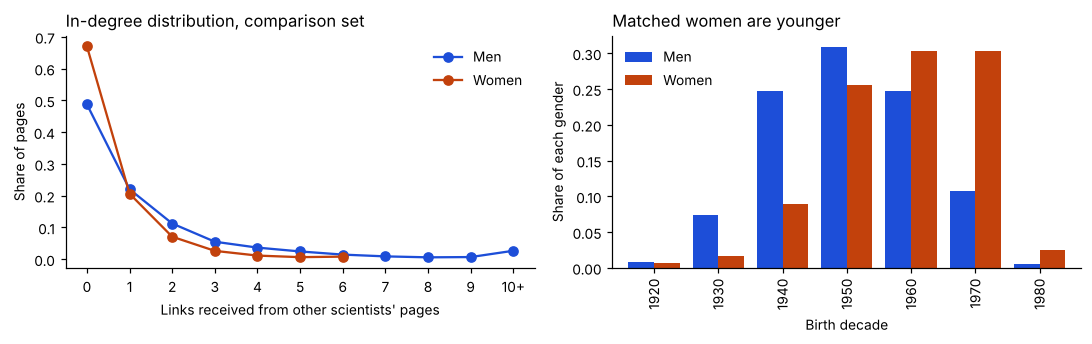

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for g in ("male", "female"):
    v = d[d.gender == g].in_degree.clip(upper=10).value_counts(normalize=True).sort_index()
    ax[0].plot(v.index, v.values, "-o", color=COL[g], label={"male": "Men", "female": "Women"}[g])
ax[0].set_xticks(range(11), [*map(str, range(10)), "10+"]); ax[0].set_xlabel("Links received from other scientists' pages")
ax[0].set_ylabel("Share of pages"); ax[0].legend(frameon=False); ax[0].set_title("In-degree distribution, comparison set", loc="left")
dec = d.groupby(["birth_decade", "gender"]).size().unstack().pipe(lambda t: t / t.sum())
dec.rename(columns={"female": "Women", "male": "Men"})[["Men", "Women"]].plot.bar(ax=ax[1], color=[COL["male"], COL["female"]], width=0.8)
ax[1].set_ylabel("Share of each gender"); ax[1].set_xlabel("Birth decade"); ax[1].set_title("Matched women are younger", loc="left"); ax[1].legend(frameon=False)
plt.tight_layout()

## 2. RQ1: embeddedness at equal impact

**Captures:** how often other scientists' biographies point to a page, and whether the page points to others.
**Misses:** links from topic, institution and prize pages; readers; why a link exists.

First the raw numbers. They are *not* at equal impact (women in the set are younger and less cited), so they only set the scene.

In [4]:
D = r1["descriptives_raw"]
pd.DataFrame({k: D[k] for k in ("in_degree", "out_degree", "reciprocal", "zero_in", "zero_out", "isolate")}).T.rename(
    index={"in_degree": "links received (mean)", "out_degree": "links given (mean)", "reciprocal": "reciprocal links (mean)",
           "zero_in": "share with no incoming link", "zero_out": "share with no outgoing link", "isolate": "share isolated"}).round(3)

,female,male
links received (mean),0.556,1.511
links given (mean),0.810,1.524
reciprocal links (mean),0.356,0.755
share with no incoming link,0.670,0.488
share with no outgoing link,0.561,0.421
share isolated,0.515,0.337


### The check: shuffle gender within strata

Keep the network fixed. Inside each cell of field × birth decade × citation quintile, shuffle who is a woman.
If women's pages received links like comparable men's, the real value would look like the shuffled ones.
Below, one small run (200 shuffles) done live; the saved run uses 1,000.

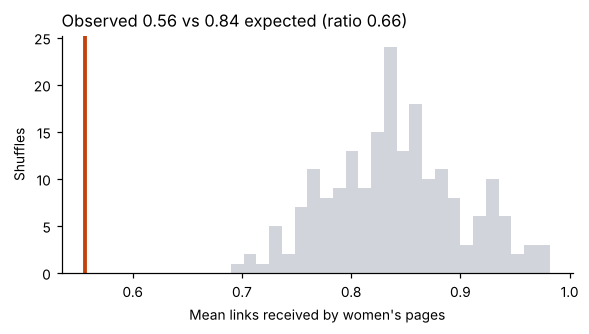

In [5]:
rng = np.random.default_rng(1); codes = pd.factorize(d.stratum)[0]; f = d.female.to_numpy(); y = d.in_degree.to_numpy(float)
null = np.array([y[permute_within(f, codes, rng) == 1].mean() for _ in range(200)])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(null, bins=25, color="#D1D5DB"); ax.axvline(y[f == 1].mean(), color=COL["female"], lw=2.5)
ax.set_xlabel("Mean links received by women's pages"); ax.set_ylabel("Shuffles")
ax.set_title(f"Observed {y[f==1].mean():.2f} vs {null.mean():.2f} expected (ratio {y[f==1].mean()/null.mean():.2f})", loc="left");

In [6]:
rows = []
for name, key in (("field x decade x citation quintile", "permutation_field_decade_citation5"), ("subfield x decade x citation tercile", "permutation_subfield_decade_citation3")):
    for k in ("in_degree", "out_degree", "reciprocal", "zero_in", "isolate"):
        p = r1[key][k]; rows.append({"strata": name, "outcome": k, "women observed": p["observed"], "expected under shuffle": p["null_mean"], "ratio": p["ratio_obs_over_null"], "z": p["z"]})
pd.DataFrame(rows).set_index(["strata", "outcome"]).round(3)

women observed  \
strata                               outcome                      
field x decade x citation quintile   in_degree            0.556   
                                     out_degree           0.810   
                                     reciprocal           0.356   
                                     zero_in              0.670   
                                     isolate              0.515   
subfield x decade x citation tercile in_degree            0.556   
                                     out_degree           0.810   
                                     reciprocal           0.356   
                                     zero_in              0.670   
                                     isolate              0.515   

                                                 expected under shuffle  \
strata                               outcome                              
field x decade x citation quintile   in_degree                    0.842   
                                     out_degree                   1.081   
                                     reciprocal                   0.466   
                                     zero_in                      0.610   
                                     isolate                      0.431   
subfield x decade x citation tercile in_degree                    0.769   
                                     out_degree                   0.999   
                                     reciprocal                   0.421   
                                     zero_in                      0.646   
                                     isolate                      0.470   

                                                 ratio      z  
strata                               outcome                   
field x decade x citation quintile   in_degree   0.661 -4.551  
                                     out_degree  0.749 -4.750  
                                     reciprocal  0.765 -3.277  
                                     zero_in     1.099  3.796  
                                     isolate     1.196  5.299  
subfield x decade x citation tercile in_degree   0.723 -3.361  
                                     out_degree  0.811 -3.542  
                                     reciprocal  0.846 -2.037  
                                     zero_in     1.037  1.594  
                                     isolate     1.096  3.176

### A second method: count models

A negative binomial regression gives the size of the gap as a rate ratio with an interval. A hurdle model splits it into
"does the page get any link?" and "how many, given at least one?". Both parts show a gap.

negative binomial   women/men = 0.60  CI [0.51 0.7 ]
Poisson, robust SE  women/men = 0.58  CI [0.49 0.68]
clustered by community        = 0.58  CI [0.48 0.7 ]
hurdle 1: any incoming link   = -9.2 points  CI [-13.8  -4.6]
hurdle 2: links | at least 1  = 0.52  CI [0.4  0.69]
old headline, log PageRank    = 0.85  CI [0.8  0.91]


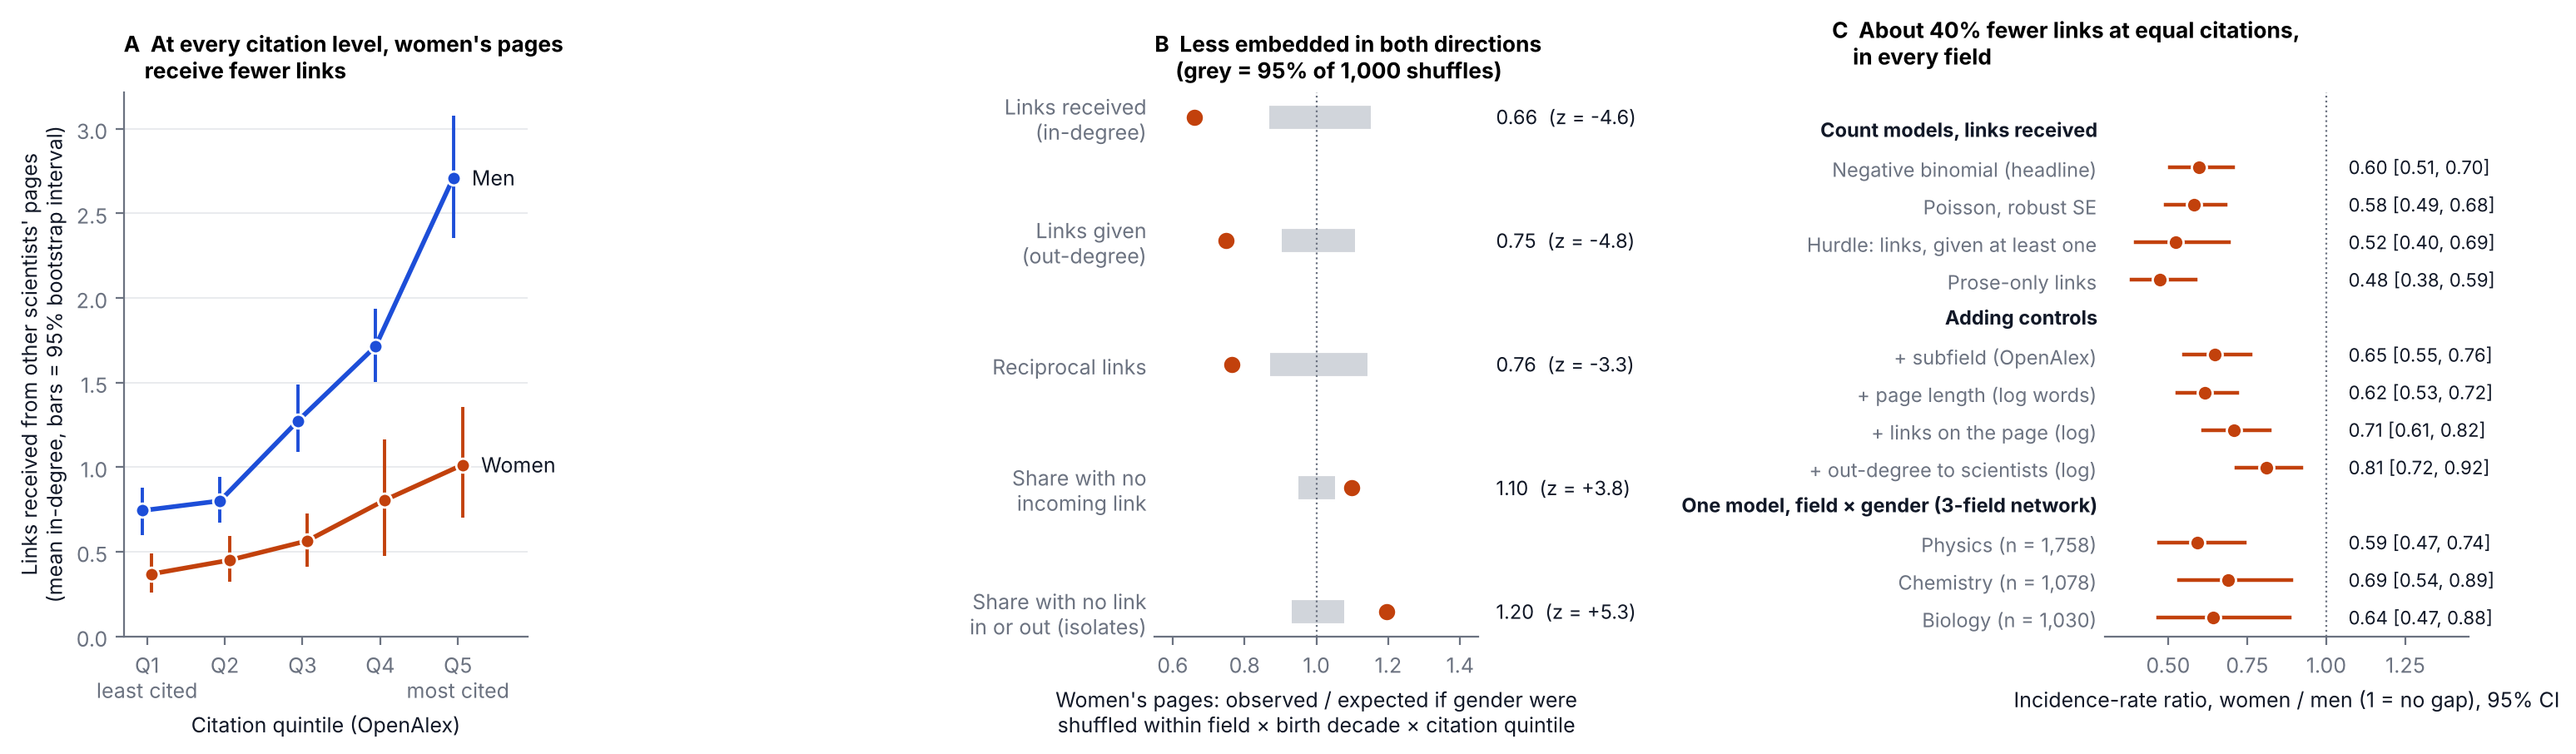

In [7]:
M = r1["models_in_degree"]; H = M["hurdle"]
print(f"negative binomial   women/men = {M['negative_binomial']['irr']:.2f}  CI {np.round(M['negative_binomial']['ci95'], 2)}")
print(f"Poisson, robust SE  women/men = {M['poisson_robust']['irr']:.2f}  CI {np.round(M['poisson_robust']['ci95'], 2)}")
print(f"clustered by community        = {r1['clustered_by_community']['irr']:.2f}  CI {np.round(r1['clustered_by_community']['ci95'], 2)}")
print(f"hurdle 1: any incoming link   = {H['any_link_diff_pct_points']:+.1f} points  CI {np.round(H['any_link_diff_ci95'], 1)}")
print(f"hurdle 2: links | at least 1  = {H['count_given_any_rate_ratio']:.2f}  CI {np.round(H['count_given_any_ci95'], 2)}")
print(f"old headline, log PageRank    = {r1['pagerank_supplement']['ratio_geometric']:.2f}  CI {np.round(r1['pagerank_supplement']['ci95'], 2)}")
display(Image(str(FIG / "fig1_embeddedness.png")))

**Figure 1.** (A) Mean links received by citation quintile. (B) Observed value for women divided by the value expected under
shuffling; the grey bar is where 95% of shuffles fall. (C) Rate ratios from the count models, with controls added, with prose-only
links, and by field.

### What the gap runs through

Adding the page's own links to the model moves the ratio toward 1. Linking is often mutual, so this is a pathway and not an
explanation that makes the gap go away: women's pages are less woven into the network in both directions.

In [8]:
display(pd.DataFrame(r1["ladder_in_degree_negbin"]).assign(ci=lambda t: t.ci95.map(lambda c: f"[{c[0]:.2f}, {c[1]:.2f}]"))[["spec", "irr", "ci"]].round(2))
F = r1["field_by_gender"]
display(pd.DataFrame(F["by_field"]).T[["n", "women", "irr", "ci95", "raw_isolate_share"]])
print("joint test that the gap differs by field: p =", round(F["joint_interaction_p"], 2))
pd.read_csv(RES / "rq1_robustness.csv")

,spec,irr,ci
0,"baseline: citations, field, decade, deceased",0.60,"[0.51, 0.70]"
1,+ subfield (OpenAlex),0.65,"[0.55, 0.76]"
2,+ page length (log words),0.62,"[0.53, 0.72]"
3,+ links on the page (log),0.71,"[0.61, 0.82]"
4,+ out-degree to scientists (log),0.81,"[0.72, 0.92]"
5,+ Nobel and awards,0.58,"[0.50, 0.67]"


,n,women,irr,ci95,raw_isolate_share
physics,1758,349,0.591281,"[0.47124262430065766, 0.7418960826870327]","{'female': 0.519, 'male': 0.34}"
chemistry,1078,240,0.690241,"[0.5350406904747451, 0.8904605261379827]","{'female': 0.504, 'male': 0.315}"
biology,1030,344,0.643491,"[0.46828721600614553, 0.8842458854887498]","{'female': 0.695, 'male': 0.558}"


joint test that the gap differs by field: p = 0.66


,variant,n,women,in_degree_ratio_perm,z,in_degree_irr_nb,irr_lo,irr_hi,out_degree_ratio_perm,isolate_ratio_perm
0,Main: all wikilinks,2926,606,0.661,-4.678,0.597,0.505,0.704,0.749,1.195
1,Prose-only links,2926,606,0.555,-4.477,0.475,0.384,0.588,0.778,1.154
2,Subfield strata + subfield control,2926,606,0.723,-3.668,0.646,0.549,0.761,0.810,1.096
3,Impact = h-index (largest profile),2926,606,0.652,-4.938,0.574,0.485,0.680,0.731,1.213
4,Single OpenAlex profile only,2491,531,0.661,-4.532,0.584,0.488,0.699,0.718,1.220
5,Without Nobel laureates,2830,600,0.684,-4.573,0.606,0.514,0.715,0.752,1.200
6,Without top 1% by citations,2896,603,0.669,-4.775,0.601,0.508,0.710,0.742,1.198
7,Born 1950 or later,2090,538,0.674,-4.066,0.608,0.506,0.731,0.768,1.169
8,Living people only,2702,579,0.661,-4.728,0.606,0.512,0.717,0.753,1.190


### Selection: who is in the comparison set?

Only pages with an ID on Wikidata can be compared at equal citations. Without a citation control we can still ask whether
the gap exists among pages that were *not* matched.

In [9]:
display(pd.DataFrame(sel["match_rate_by_decade"]).T.round(2))
pd.DataFrame({k: {"n": v["n"], "women": v["women"], "NB rate ratio": v["negbin_irr"]["irr"], "CI low": v["negbin_irr"]["ci95"][0], "CI high": v["negbin_irr"]["ci95"][1]}
              for k, v in sel["gap_without_citation_control"].items()}).T.round(2)

,women,men,n_women,n_men
1920,0.02,0.01,177.0,1706.0
1930,0.06,0.10,170.0,1813.0
1940,0.23,0.30,238.0,1902.0
1950,0.49,0.50,317.0,1435.0
1960,0.64,0.62,287.0,934.0
1970,0.72,0.62,255.0,399.0
1980,0.75,0.60,20.0,20.0


,n,women,NB rate ratio,CI low,CI high
all pages,9673.0,1464.0,0.50,0.45,0.55
matched (comparison set),2926.0,606.0,0.51,0.44,0.59
not matched,6747.0,858.0,0.50,0.43,0.58


## 3. RQ3: who links to women's pages?

**Captures:** same-gender linking. **Misses:** the reason (collaboration, shared prizes, the same editors).

The old null shuffled gender within field × decade. The revised null shuffles within link community × decade, so topical
clustering of women cannot produce the result. Louvain communities change with the seed, so this is repeated over 10 partitions.

154 of 696 links to women's pages come from women's pages = 22.1%


seed,0,1,2,3,4,5,6,7,8,9
community,0.126,0.127,0.123,0.127,0.124,0.128,0.124,0.127,0.128,0.125
community_x_decade,0.134,0.135,0.131,0.135,0.133,0.137,0.135,0.137,0.132,0.137
z (community x decade),7.200,6.500,7.300,7.300,7.100,6.600,6.200,6.900,7.000,6.800


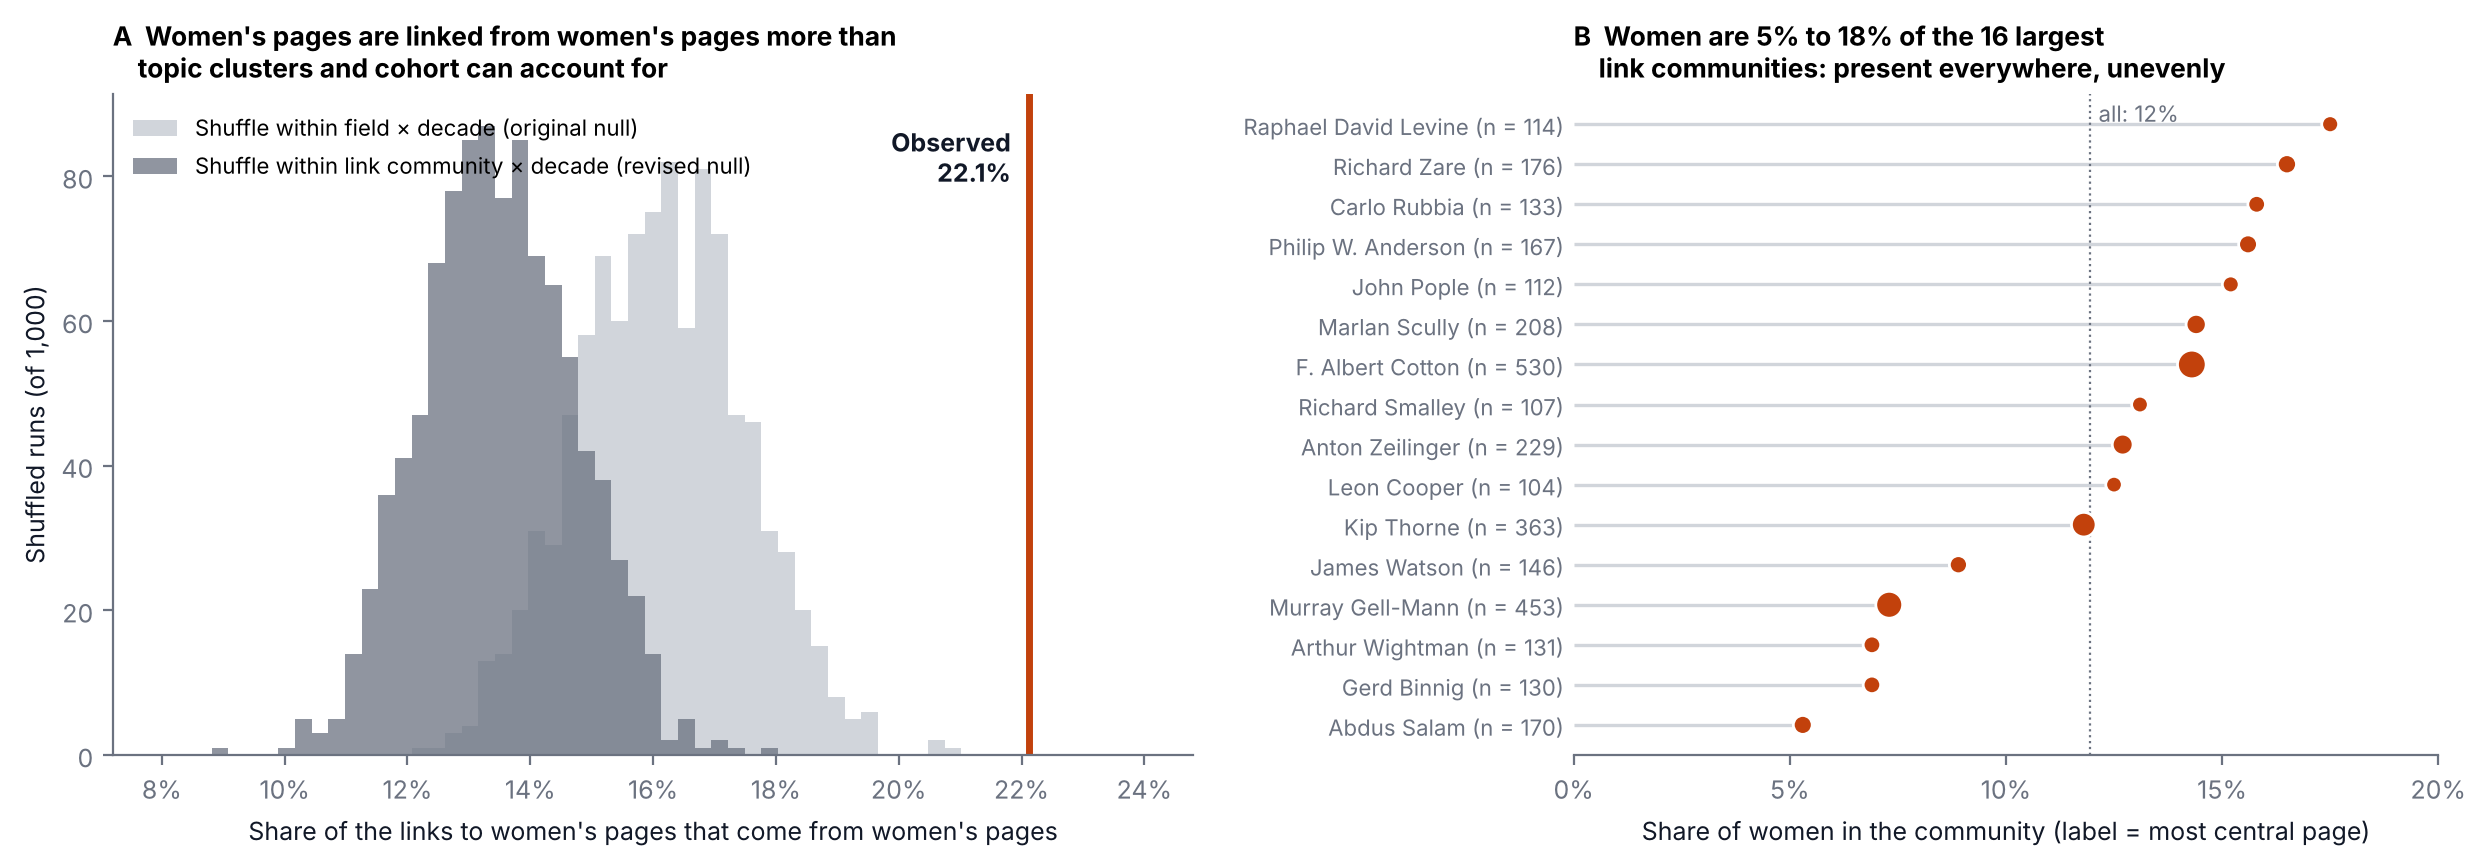

In [10]:
print(f"{r3['women_to_women_edges']} of {r3['edges_to_women']} links to women's pages come from women's pages = {r3['observed_share_from_women']:.1%}")
display(pd.DataFrame([{"seed": s["seed"], **{k: round(s[k]["null_mean"], 3) for k in ("community", "community_x_decade")}, "z (community x decade)": round(s["community_x_decade"]["z"], 1)} for s in r3["by_louvain_seed"]]).set_index("seed").T)
display(Image(str(FIG / "fig3_homophily.png")))

**Figure 3.** (A) Observed share against both nulls. (B) Share of women in each link community with at least 100 pages.

## 4. RQ2: how the pages are written

**Captures:** whether wording differs systematically once names, pronouns and gender words are masked.
**Misses:** what the difference is about. A classifier can pick up who wrote the page as easily as how the person is described.

metadata only (field, decade, citations, length):  AUC 0.712
pooled_auc                 observed 0.859 | shuffled 0.576 [0.545 0.605] | z = 16.8
within_field_decade_auc    observed 0.846 | shuffled 0.497 [0.456 0.534] | z = 17.6

strongest classifier words, women's side: education, completed, recognition, career, aps, earned, fellowship, research, joined, interested, researcher, moved, how, life, nomination, postdoctoral, doctorate, french, materials, young, won, who, master, elected, studied
strongest classifier words, men's side:   prize, received, emeritus, under, nobel, visiting, japan, china, founding, subsequently, august, academic, field, theory, discovered, with, mechanics, october, later, served, now, among, called, notable, years


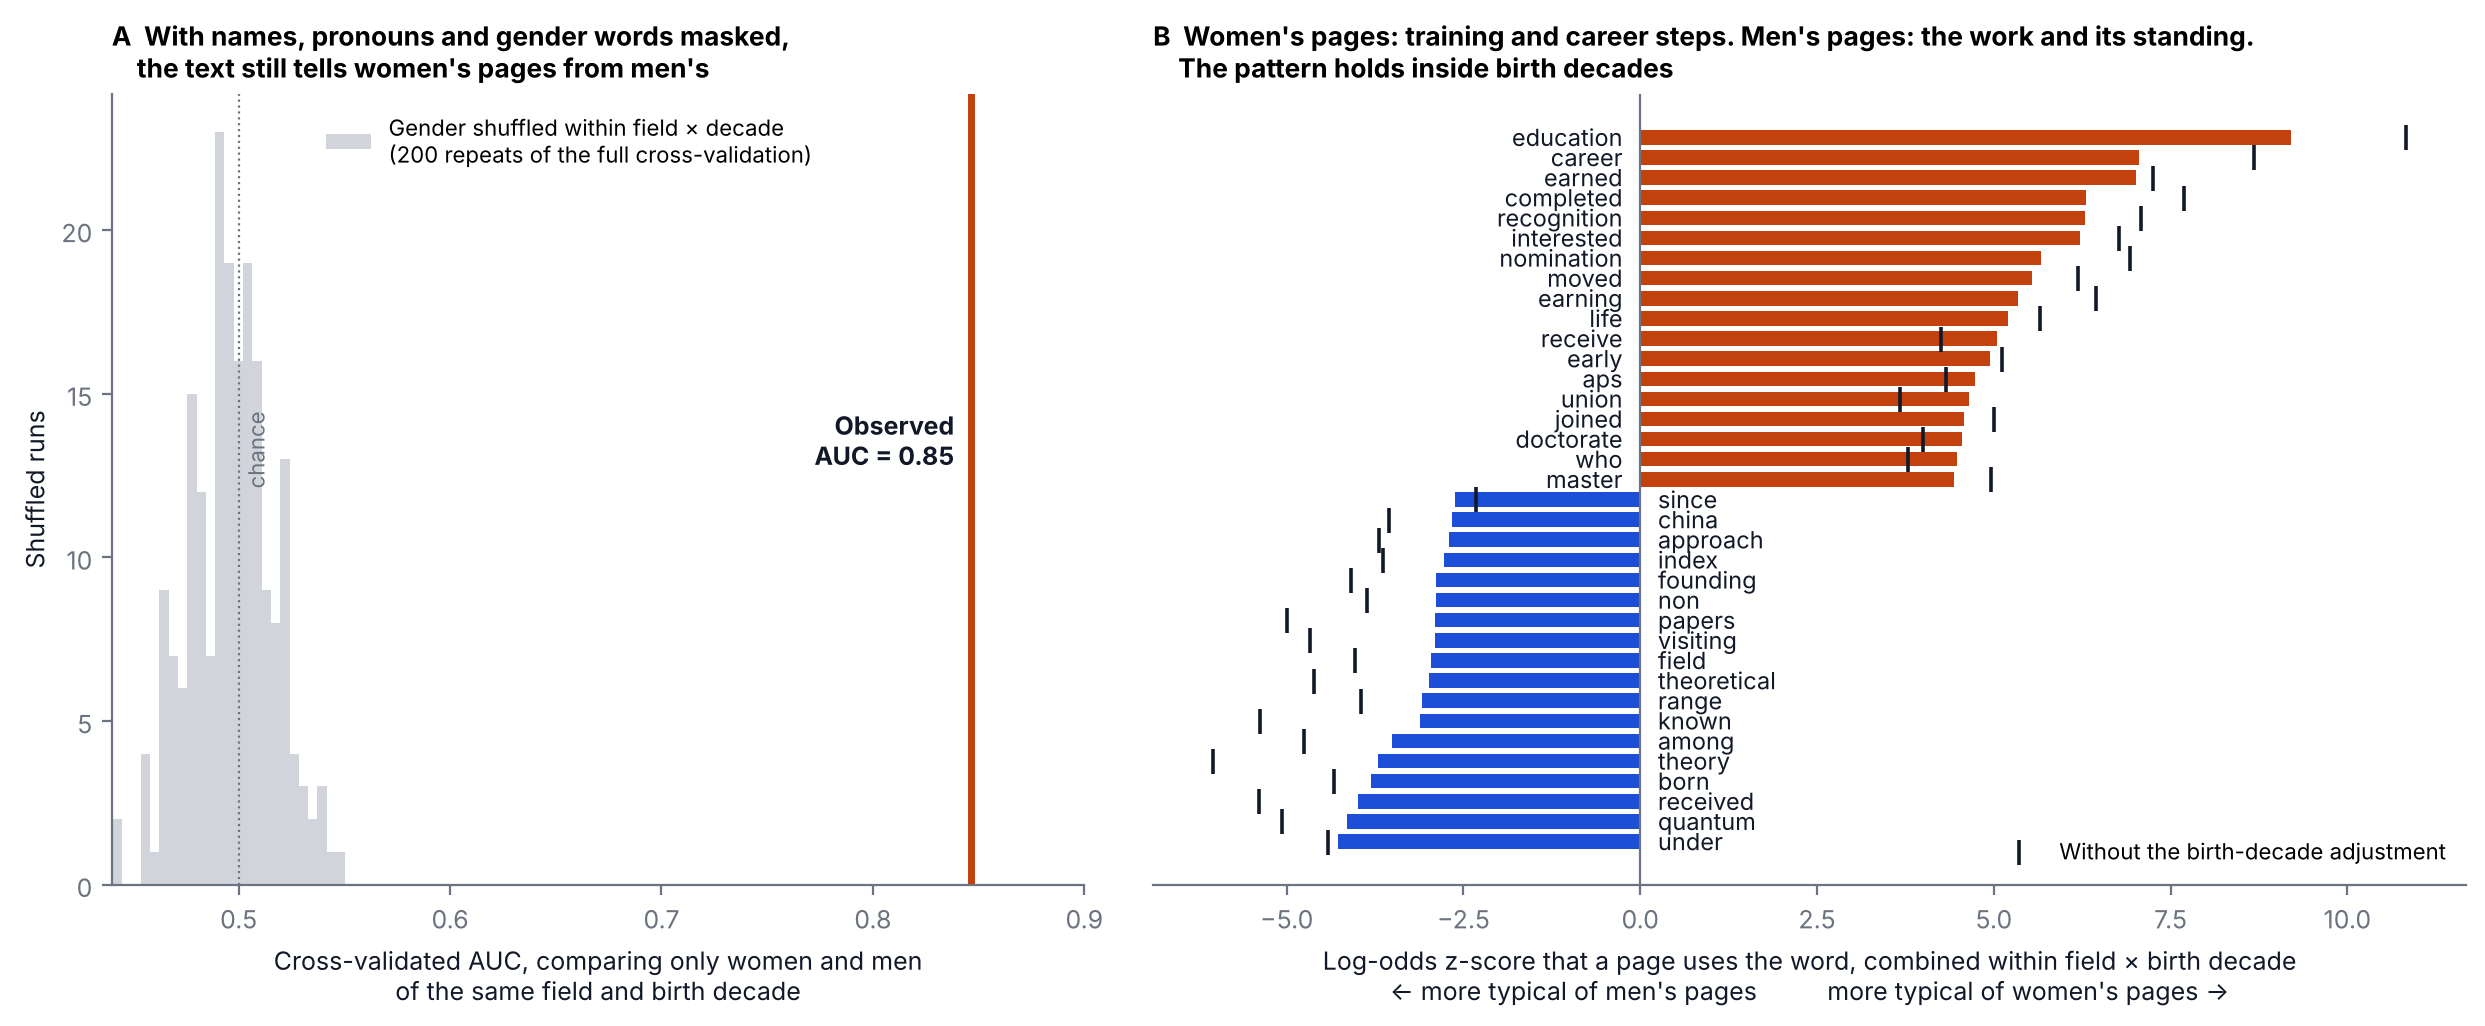

In [11]:
c = r2["classifier_strict_masking"]
print("metadata only (field, decade, citations, length):  AUC", round(r2["metadata_only_auc"], 3))
for k in ("pooled_auc", "within_field_decade_auc"):
    print(f"{k:<26} observed {c[k]['observed']:.3f} | shuffled {c[k]['null_mean']:.3f} {np.round(c[k]['null_ci95'], 3)} | z = {c[k]['z']:.1f}")
print("\nstrongest classifier words, women's side:", ", ".join(c["top_features_women"][:25]))
print("strongest classifier words, men's side:  ", ", ".join(c["top_features_men"][:25]))
display(Image(str(FIG / "fig2_text.png")))

**Figure 2.** (A) Cross-validated AUC within field × decade against 200 re-runs with shuffled gender. (B) Words by log-odds
z-score within field × birth decade; the tick marks show the value without the decade adjustment.

A caveat we found ourselves: British spellings and a recognisable biography style are among the women-side words.

In [12]:
fw = pd.read_csv(RES / "rq2_words.csv").set_index("word")
display(fw.loc[["whilst", "honours", "characterisation", "considers", "postdoctoral", "earned", "theory", "papers"], ["share_women", "share_men", "z_pooled", "z_within_field_decade", "z_young_vs_old_men"]].round(3))
print("held-out replication:", r2["words"]["split_half"])
print("explicit gender mentions:", r2["explicit_gender_mentions"])

,share_women,share_men,z_pooled,z_within_field_decade,z_young_vs_old_men
word,,,,,
whilst,0.025,0.006,3.975,3.101,1.845
honours,0.226,0.151,4.384,4.306,-1.664
characterisation,0.018,0.004,3.351,2.740,1.535
considers,0.056,0.005,7.202,4.431,1.035
postdoctoral,0.450,0.304,6.693,3.521,5.950
earned,0.310,0.175,7.257,7.011,-1.773
theory,0.170,0.295,-6.044,-3.713,-2.776
papers,0.089,0.175,-4.989,-2.899,-3.570


held-out replication: {'splits': 100, 'top60_same_sign_in_held_out_half_mean': 0.9346666666666669, 'top60_same_sign_range': [0.8666666666666667, 1.0], 'top60_same_sign_and_abs_z_above_1.96_mean': 0.41600000000000004, 'chance_level_same_sign': 0.5}
explicit gender mentions: {'share_women': 0.1551155115511551, 'share_men': 0.001293103448275862, 'adjusted_diff_pct_points': 16.605135377244505, 'ci95': [13.539365757889781, 19.670904996599226]}


## 5. Validation status

The blind sheets in `../validation/` are waiting for two human labellers. Until `r5_validation.py score` has been run,
the only labels are AI-assisted.

In [13]:
import os
for f in sorted(os.listdir(VAL)):
    if f.endswith(".csv"):
        t = pd.read_csv(VAL / f); col = "correct" if "matches" in f else "is_personal"
        print(f"{f:<32} {t[col].notna().sum():>3} of {len(t)} rows labelled")

matches_labeller_A.csv             0 of 100 rows labelled
matches_labeller_B.csv             0 of 100 rows labelled
sentences_labeller_A.csv           0 of 300 rows labelled
sentences_labeller_B.csv           0 of 300 rows labelled


## 6. Conclusions

See `../CONCLUSIONS.md` for the full tables. In short:

1. At equal citations, field and birth decade, women's pages receive about 40% fewer links from other scientists' pages. They also give fewer links and are more often isolated: less embedded in both directions.
2. The gap holds with subfield strata, with prose-only links (where it is larger), without Nobel laureates, among living people, and in physics, chemistry and biology alike. It is the same size among pages that could not be matched to OpenAlex.
3. Links to women's pages come from women's pages more than topic clusters and cohort account for.
4. The masked text still separates women's from men's pages. The words point to training and career steps on women's pages and to the work and its standing on men's, but page authorship is an untested alternative.
5. Open: human validation, the name-match selection check, and page creation dates.